# Replicating ssBV-n with Dynamical Decoupling (Qiskit 2.5)

Reimplementation of the core experimental result from **Pokharel & Lidar,
"Demonstration of algorithmic quantum speedup," arXiv:2207.07647 (2022)**:
the single-shot Bernstein-Vazirani circuit, executed with and without
**dynamical decoupling (DD)**, on a real IBM Quantum backend.

**Scope of this notebook (Stage 1):**
- Build the ssBV-n oracle circuit exactly as in Fig. 1 of the paper.
- Construct the paper's UR-14 dynamical-decoupling pulse sequence (Appendix F)
  and insert it into idle-qubit windows via Qiskit's transpiler passes.
- Validate correctness on a noiseless simulator, rehearse on a noisy local
  simulator seeded from the real backend's calibration, then run on real
  IBM Quantum hardware within a small, explicit QPU-time budget.
- Compare success probability with vs. without DD, reproducing the
  qualitative result of the paper's Fig. 2 (BV-6).

**Deferred to a later stage** (see `Experiment Plan.md`): multi-*n*
time-to-solution scaling, bootstrapped confidence intervals, the speedup
exponent &lambda;, and the paper's custom CNOT-efficient ancilla-swap routing
(Appendix D) &mdash; this notebook relies on Qiskit's standard transpiler for
qubit routing instead.

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import bv_dd_lib as bv

## 1. Connect to IBM Quantum and pick a backend

You need two things from the [IBM Quantum Platform dashboard](https://quantum.cloud.ibm.com/):
an **API key** (Token) and an **Instance CRN** (a service instance/project
identifier -- shown on the same dashboard, looks like
`crn:v1:bluemix:public:quantum-computing:...`). Paste them into
`IBM_QUANTUM_TOKEN` / `IBM_QUANTUM_INSTANCE` below.

**Security note:** this notebook will contain your live token in plain text
once you fill it in below -- don't commit it or share the file as-is.
Two safer alternatives, either works with the cell below unchanged:
- Set the `IBM_QUANTUM_TOKEN` / `IBM_QUANTUM_INSTANCE` environment variables
  instead of editing this cell, or
- Run `QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token="...", instance="...")`
  once in a separate, throwaway cell (or the terminal) and delete it -- future
  runs of the cell below then fall back to that saved account automatically,
  with no credentials in this file at all.

This also picks whichever of `ibm_fez` / `ibm_marrakesh` (Heron r2, Open
Plan-eligible) is actually available on your account, rather than assuming
one.

In [32]:
import os

from qiskit_ibm_runtime import QiskitRuntimeService

# Paste your credentials here, or leave the placeholders to use environment
# variables / a previously saved account instead (see the note above).
IBM_QUANTUM_TOKEN = os.environ.get("MY_TOKEN")
IBM_QUANTUM_INSTANCE = os.environ.get("MY_INSTANCE")

if IBM_QUANTUM_TOKEN and not IBM_QUANTUM_TOKEN.startswith("PASTE_"):
    service = QiskitRuntimeService(
        channel="ibm_quantum_platform",
        token=IBM_QUANTUM_TOKEN,
        instance=IBM_QUANTUM_INSTANCE if not IBM_QUANTUM_INSTANCE.startswith("PASTE_") else None,
    )
else:
    service = QiskitRuntimeService()  # falls back to a previously saved account

PREFERRED_BACKENDS = ["ibm_fez", "ibm_marrakesh"]
available = {b.name for b in service.backends()}
backend_name = next((name for name in PREFERRED_BACKENDS if name in available), None)
if backend_name is None:
    raise RuntimeError(
        f"Neither of {PREFERRED_BACKENDS} is available on this account. "
        f"Available backends: {sorted(available)}"
    )

backend = service.backend(backend_name)
print(f"Using backend: {backend.name}  ({backend.num_qubits} qubits)")

qiskit_runtime_service._discover_account:WARNING:2026-09-23 00:32:31,567: Loading account with the given token. A saved account will not be used.


Using backend: ibm_fez  (156 qubits)


## 2. Build the ssBV-6 oracle circuits (Fig. 1)

We use the paper's own representative-oracle trick: for problem size *n*,
testing the *n*+1 bitstrings `b = 1^k 0^(n-k)` (one per Hamming weight `k`)
is enough, since circuits for any two bitstrings of the same weight are
identical up to qubit relabeling. `N = 6` deliberately matches the paper's
own Fig. 2 example, so results are visually comparable to a published
reference point.

7 representative oracles for n=6: ['000000', '100000', '110000', '111000', '111100', '111110', '111111']


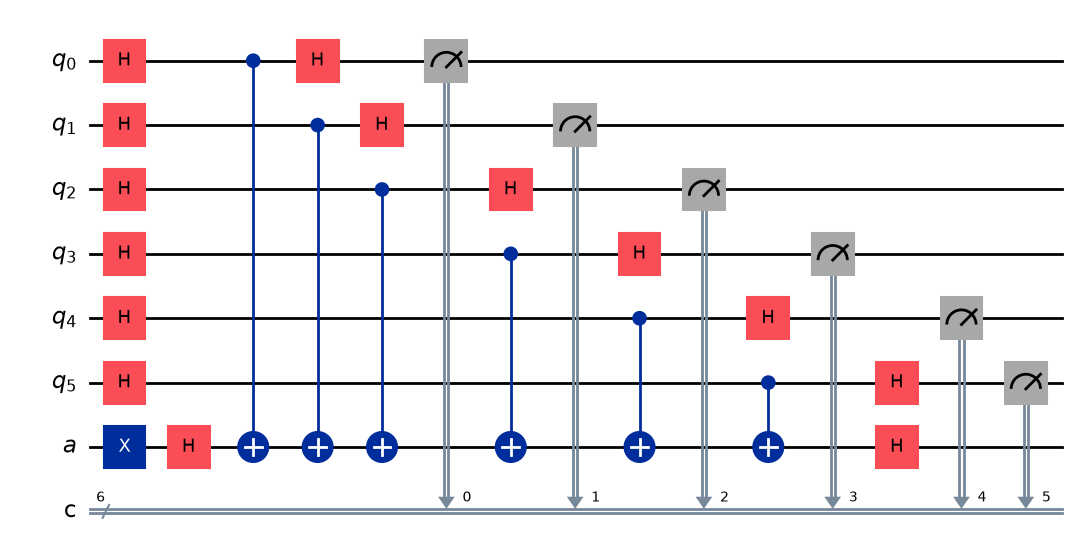

In [33]:
N = 6
labels = bv.all_representative_oracles(N)
print(f"{len(labels)} representative oracles for n={N}: {labels}")

circuits = {label: bv.build_bv_circuit(label) for label in labels}
circuits[labels[-1]].draw("mpl")

## 3. Construct the UR-14 dynamical decoupling sequence (Appendix F)

`ur_n_phases` implements the paper's closed-form UR*n* formula: pulse axis
angles `phi_k = [(k-1)(k-2)/2] * Phi^(n) + (k-1)*phi_2`. One subtlety not
spelled out in the appendix: the sequence's net effect is a phase gate
`exp(i*chi*Z)` with `chi = n*phi_2/2` (Genov et al. 2017, arXiv:1609.09416,
the paper this appendix cites); pure dynamical decoupling needs `chi = 0`,
which constrains `phi_2` to specific multiples of `2*pi/n`. The paper's
stated "phi_2 = pi/2" satisfies that automatically when `n` is a multiple of
4 (giving UR4 = XY4, as the paper notes) but *not* when `n = 4m+2` -- which
is exactly UR14 and UR18, the two sequences the paper actually uses. For
that branch we instead use `phi_2 = Phi^(n)`, verified below and
cross-checked against the original paper's own worked UR6 example.

`ur_n_sequence` then realizes each pulse in the backend's native basis: IBM
targets don't expose a general arbitrary-axis rotation gate, only virtual
`RZ` plus a physical `X` (and `SX`), so each pulse becomes `RZ(phi_k)` -
`X` - `RZ(-phi_k)` -- a virtual-Z frame change around a physical X pulse,
which is also how transmon control electronics implement an arbitrary pulse
axis in practice. Before this ever touches a circuit, we check that the
full sequence's matrices multiply to the identity (up to global phase) --
the same check Qiskit's `PadDynamicalDecoupling` pass performs internally,
so passing this guarantees the pass will accept it.

In [27]:
UR_LENGTH = 14
ur14 = bv.ur_n_sequence(UR_LENGTH)
assert bv.verify_dd_sequence_identity(ur14), "UR-14 sequence does not compose to identity"
print(f"UR-{UR_LENGTH} verified: {len(ur14)} native gates ({UR_LENGTH} RZ-X-RZ pulses), "
      f"product of matrices = identity (up to global phase)")

phases_deg = [round(np.degrees(p), 1) for p in bv.ur_n_phases(UR_LENGTH)]
print("Pulse axis angles (degrees):", phases_deg)

UR-14 verified: 42 native gates (14 RZ-X-RZ pulses), product of matrices = identity (up to global phase)
Pulse axis angles (degrees): [np.float64(0.0), np.float64(154.3), np.float64(462.9), np.float64(925.7), np.float64(1542.9), np.float64(2314.3), np.float64(3240.0), np.float64(4320.0), np.float64(5554.3), np.float64(6942.9), np.float64(8485.7), np.float64(10182.9), np.float64(12034.3), np.float64(14040.0)]


## 3b. IBM Runtime's built-in DD sequences (for comparison)

Alongside our own UR-14 construction, `qiskit-ibm-runtime`'s `SamplerV2` ships
three built-in `dynamical_decoupling` presets (`XX`, `XpXm`, `XY4` --
`qiskit_ibm_runtime.options.DynamicalDecouplingOptions`). On real hardware
(Section 8) these are applied as a per-job Runtime *option*
(`run_on_hardware_builtin_dd`), not through our own `PadDynamicalDecoupling`
pass -- so, unlike UR-14, they can't be scheduled/inserted locally by us for
the actual submission. But for the correctness gate and noisy dress
rehearsal below, we reconstruct the equivalent native gate lists locally
(`bv.ibm_builtin_dd_sequence`) using the same RZ-X-RZ pulse-axis convention
as `ur_n_sequence`, so we can simulate and budget-estimate them the same way
as UR-14.

**Caveat:** `XX` and `XpXm` are unitarily identical up to a global phase (a
physical `-X` pulse and `+X` pulse implement the same qubit rotation up to
an unobservable phase) -- local simulation cannot distinguish them, and the
two columns below will match exactly. Any real difference between them is a
hardware-only effect of the physical pulse phase, which is the whole reason
`XpXm` exists as an error-compensating variant of `XX`.

In [34]:
builtin_sequences = {name: bv.ibm_builtin_dd_sequence(name) for name in ["XX", "XpXm", "XY4"]}
for name, seq in builtin_sequences.items():
    assert bv.verify_dd_sequence_identity(seq), f"{name} sequence does not compose to identity"
    print(f"{name}: {len(seq)} native gates ({len(seq) // 3} RZ-X-RZ pulses), verified identity")

XX: 6 native gates (2 RZ-X-RZ pulses), verified identity
XpXm: 6 native gates (2 RZ-X-RZ pulses), verified identity
XY4: 12 native gates (4 RZ-X-RZ pulses), verified identity


## 4. Transpile: bare ("free") and DD-protected ISA circuits

Each oracle is transpiled once to the backend's ISA (Qiskit's standard
Sabre-based routing -- see `Experiment Plan.md` for why we're not using
the paper's custom ancilla-swap router here), then split into scheduled
variants: `free` (ALAP-scheduled, no padding) and four DD-padded variants
-- `dd` (UR-14, the paper's "decouple then compute" strategy) plus `xx`,
`xpxm`, `xy4` (locally-reconstructed equivalents of IBM Runtime's built-in
presets, used for the correctness gate, dress rehearsal, and budget
estimate in Sections 5-7; the real hardware run in Section 8 instead uses
Runtime's own built-in option on the unscheduled routed circuit). Each
variant gets a unique circuit name so all five can be safely batched into
jobs later -- without this, variants would collide under the same name,
since they all derive from the same source circuit.

In [35]:
free_isa, dd_isa = {}, {}
builtin_isa = {name: {} for name in builtin_sequences}
routed_isa = {}

for label, qc in circuits.items():
    isa = bv.to_isa_circuit(qc, backend)
    routed_isa[label] = isa

    free_c = bv.schedule_only(isa, backend)
    free_c.name = f"bv_{label}_free"
    free_isa[label] = free_c

    dd_c = bv.add_dynamical_decoupling(isa, backend, ur14)
    dd_c.name = f"bv_{label}_dd"
    dd_isa[label] = dd_c

    for name, seq in builtin_sequences.items():
        variant_c = bv.add_dynamical_decoupling(isa, backend, seq)
        variant_c.name = f"bv_{label}_{name.lower()}"
        builtin_isa[name][label] = variant_c

example = labels[-1]
print(f"Oracle {example}: free  depth={free_isa[example].depth()}, duration={free_isa[example].duration} dt")
print(f"Oracle {example}: DD    depth={dd_isa[example].depth()}, duration={dd_isa[example].duration} dt")
for name in builtin_sequences:
    c = builtin_isa[name][example]
    print(f"Oracle {example}: {name:<5} depth={c.depth()}, duration={c.duration} dt")

Oracle 111111: free  depth=40, duration=742 dt
Oracle 111111: DD    depth=121, duration=742 dt
Oracle 111111: XX    depth=59, duration=742 dt
Oracle 111111: XpXm  depth=59, duration=742 dt
Oracle 111111: XY4   depth=95, duration=742 dt


C:\Users\LOQ\AppData\Local\Temp\ipykernel_21052\1397724067.py:23: DeprecationWarning: The property ``qiskit.circuit.quantumcircuit.QuantumCircuit.duration`` is deprecated as of Qiskit 1.3.0. It will be removed in Qiskit 3.0.0.
  print(f"Oracle {example}: free  depth={free_isa[example].depth()}, duration={free_isa[example].duration} dt")
C:\Users\LOQ\AppData\Local\Temp\ipykernel_21052\1397724067.py:24: DeprecationWarning: The property ``qiskit.circuit.quantumcircuit.QuantumCircuit.duration`` is deprecated as of Qiskit 1.3.0. It will be removed in Qiskit 3.0.0.
  print(f"Oracle {example}: DD    depth={dd_isa[example].depth()}, duration={dd_isa[example].duration} dt")
C:\Users\LOQ\AppData\Local\Temp\ipykernel_21052\1397724067.py:27: DeprecationWarning: The property ``qiskit.circuit.quantumcircuit.QuantumCircuit.duration`` is deprecated as of Qiskit 1.3.0. It will be removed in Qiskit 3.0.0.
  print(f"Oracle {example}: {name:<5} depth={c.depth()}, duration={c.duration} dt")


### 4a. Idle-time utilization: is DD actually covering the idle windows?

Depth and duration alone don't reveal *where* the extra depth is going. In particular,
`PadDynamicalDecoupling` inserts a sequence into an idle window only if the window is at least
as long as the sequence's total pulse duration -- if it's shorter, the pass silently falls back
to a single bare (unprotected) `Delay` for that window, with no warning. `bv.dd_utilization_summary`
recomputes that pass/fail check per window directly from the backend's calibrated gate durations
(mirroring Qiskit's own `slack` calculation) and cross-checks it against how much `Delay` time
actually remains in each padded circuit, so we can see -- per variant -- how much of the oracle's
idle time ended up genuinely pulse-covered vs. left as buffer or skipped outright.

In [41]:
import importlib
importlib.reload(bv)

utilization = bv.dd_utilization_summary(
    free_isa[example],
    {"dd": dd_isa[example], **{name: builtin_isa[name][example] for name in builtin_sequences}},
    {"dd": ur14, **builtin_sequences},
    backend,
)
display(utilization)

utilization = bv.dd_utilization_report(free_isa[example], dd_isa[example], backend, ur14)

display(utilization)


,total_idle_dt,pulse_covered_dt,buffer_or_skipped_dt,utilization_pct,windows_skipped,qubits_with_skips
variant,,,,,,
dd,2032,336,1696,16.535433,5,5
XX,2032,96,1936,4.724409,0,0
XpXm,2032,96,1936,4.724409,0,0
XY4,2032,168,1864,8.267717,2,2


,n_windows,total_idle_dt,predicted_pulse_covered_dt,predicted_skipped_windows,actual_pulse_covered_dt,buffer_or_skipped_dt,utilization_pct
qubit,,,,,,,
123,1,212,84,0,84,128,39.622642
124,2,258,84,1,84,174,32.558140
136,2,201,84,1,84,117,41.791045
141,2,258,84,1,0,258,0.000000
142,2,212,84,1,0,212,0.000000
143,3,593,168,1,84,509,14.165261
144,1,298,84,0,0,298,0.000000


### A closer look: DD pulses filling idle windows

`idle_wires=False` hides the backend qubits our circuit never touches, so
only the physical qubits actually routed to are shown -- otherwise this
would draw one wire per backend qubit (100+), almost all empty.

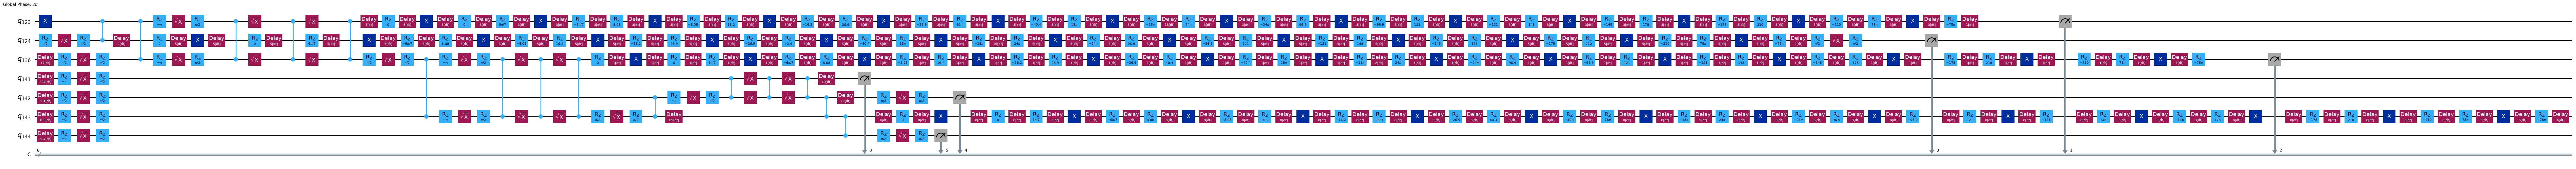

In [7]:
dd_isa[example].draw("mpl", idle_wires=False, fold=-1)

## 5. Correctness gate: ideal (noiseless) simulation

Every oracle, both variants, must show success probability **1.0** here.
DD pulses are logically transparent when applied correctly -- a failure in
this cell means the UR-14 construction or padding is wrong, not that "DD
doesn't work." This runs locally; no QPU time is used.

In [8]:
free_list = [free_isa[label] for label in labels]
dd_list = [dd_isa[label] for label in labels]
builtin_list = {name: [builtin_isa[name][label] for label in labels] for name in builtin_sequences}
variant_cols = ["free", "dd"] + list(builtin_sequences)
variant_lists = {"free": free_list, "dd": dd_list, **builtin_list}

# One combined circuit list, positionally sliced back per variant below -- avoids rebuilding the
# (expensive, backend-sized) noise model once per variant in the noisy dress rehearsal (Section 6).
combined_circuits = [c for col in variant_cols for c in variant_lists[col]]

def _split_by_variant(counts):
    return {col: dict(zip(labels, counts[i * len(labels):(i + 1) * len(labels)])) for i, col in enumerate(variant_cols)}

ideal_by_variant = _split_by_variant(bv.run_ideal(combined_circuits, shots=1000))

ideal_comparison = bv.compare_variants(ideal_by_variant, labels)
display(ideal_comparison)

assert (ideal_comparison[variant_cols] > 0.999).all().all(), \
    "Ideal success probability should be 1.0 for all oracles -- check DD construction before continuing."
print("Ideal-simulator correctness check passed.")

,weight,free,dd,XX,XpXm,XY4
oracle,,,,,,
000000,0,1.0,1.0,1.0,1.0,1.0
100000,1,1.0,1.0,1.0,1.0,1.0
110000,2,1.0,1.0,1.0,1.0,1.0
111000,3,1.0,1.0,1.0,1.0,1.0
111100,4,1.0,1.0,1.0,1.0,1.0
111110,5,1.0,1.0,1.0,1.0,1.0
111111,6,1.0,1.0,1.0,1.0,1.0


Ideal-simulator correctness check passed.


## 6. Dress rehearsal: noisy local simulation

`AerSimulator.from_backend(backend)` pulls a live calibration snapshot from
the real backend (no QPU quota used) and simulates with that noise model.
DD-protected success probability should be directionally **>=** the bare
success probability on average, matching the paper's qualitative Fig. 2
result -- this is the gate to clear before spending real QPU time below.

,weight,free,dd,XX,XpXm,XY4
oracle,,,,,,
000000,0,0.8880,0.8765,0.890,0.8720,0.8720
100000,1,0.9730,0.9740,0.974,0.9745,0.9750
110000,2,0.9700,0.9725,0.965,0.9675,0.9695
111000,3,0.9545,0.9585,0.960,0.9585,0.9565
111100,4,0.9345,0.9285,0.927,0.9310,0.9255
111110,5,0.9205,0.9080,0.918,0.9185,0.9075
111111,6,0.8955,0.9040,0.893,0.8925,0.9035


Average success probability -- free: 0.934, dd: 0.932, XX: 0.932, XpXm: 0.931, XY4: 0.930


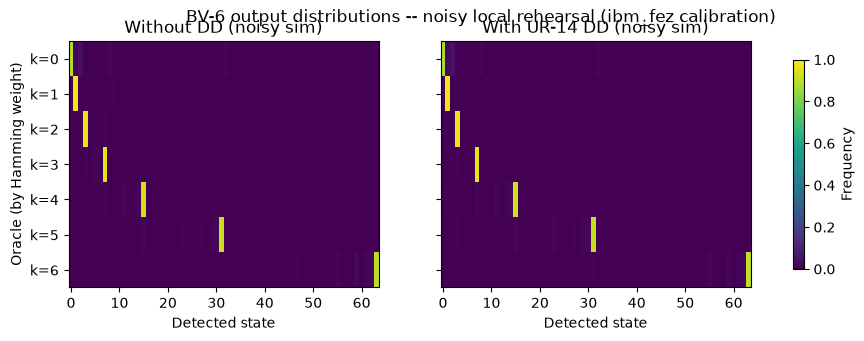

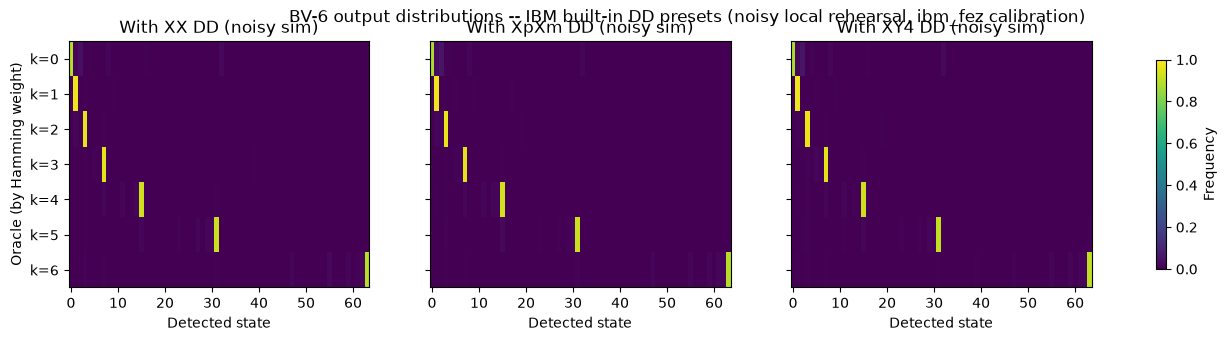

In [9]:
noisy_by_variant = _split_by_variant(bv.run_noisy_local(combined_circuits, backend, shots=2000))
noisy_free = noisy_by_variant["free"]
noisy_dd = noisy_by_variant["dd"]
noisy_builtin = {name: noisy_by_variant[name] for name in builtin_sequences}

noisy_comparison = bv.compare_variants(noisy_by_variant, labels)
display(noisy_comparison)
print("Average success probability -- " + ", ".join(f"{col}: {noisy_comparison[col].mean():.3f}" for col in variant_cols))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
_, im0 = bv.plot_output_distributions(noisy_free, labels, N, "Without DD (noisy sim)", ax=axes[0])
_, im1 = bv.plot_output_distributions(noisy_dd, labels, N, "With UR-14 DD (noisy sim)", ax=axes[1])
axes[0].set_ylabel("Oracle (by Hamming weight)")
fig.colorbar(im1, ax=axes, label="Frequency", shrink=0.85)
fig.suptitle(f"BV-{N} output distributions -- noisy local rehearsal ({backend.name} calibration)")
plt.show()

fig2, axes2 = plt.subplots(1, len(builtin_sequences), figsize=(5.5 * len(builtin_sequences), 3.2), sharey=True)
for ax, name in zip(axes2, builtin_sequences):
    _, im2 = bv.plot_output_distributions(noisy_builtin[name], labels, N, f"With {name} DD (noisy sim)", ax=ax)
axes2[0].set_ylabel("Oracle (by Hamming weight)")
fig2.colorbar(im2, ax=axes2, label="Frequency", shrink=0.85)
fig2.suptitle(f"BV-{N} output distributions -- IBM built-in DD presets (noisy local rehearsal, {backend.name} calibration)")
plt.show()

## 7. QPU budget check

Sums scheduled circuit duration &times; shots across the full batch and
compares against a configurable ceiling, kept well under the free Open
Plan's ~10-minutes-per-28-days quota. This includes the locally-padded
`xx`/`xpxm`/`xy4` circuits from Section 4 as a duration proxy for the
built-in-DD hardware jobs in Section 8 -- DD padding doesn't change total
scheduled duration (ALAP-schedule-then-pad just fills existing idle slots),
so the local reconstruction's duration matches what Runtime's own
scheduler will produce for the same sequence type. Reduce `SHOTS` or `N`
above if this prints "OVER BUDGET".

In [10]:
SHOTS = 2000
QPU_BUDGET_SECONDS = 240  # comfortably under the ~600s/28-day Open Plan quota

all_circuits = free_list + dd_list  # the one job submitted in Section 8 for free + UR-14 DD
builtin_circuits_flat = [c for name in builtin_sequences for c in builtin_list[name]]
budget_ok = bv.check_budget(all_circuits + builtin_circuits_flat, SHOTS, backend, budget_seconds=QPU_BUDGET_SECONDS)

Estimated QPU time: 2.16s  (budget: 240s)  -> OK


## 8. Real-hardware run

**This cell spends real IBM Quantum QPU quota.** Only set `SUBMIT = True`
once the budget check above prints OK and the noisy rehearsal in Section 6
shows DD helping. `free` and `dd` (UR-14) are batched into a single
`SamplerV2` job (one job, minimizing per-job overhead), same as before.
The three built-in presets (`xx`, `xpxm`, `xy4`) each need their own job,
since `options.dynamical_decoupling` is a per-job Runtime setting rather
than a per-circuit transpiler pass -- so this cell submits four jobs total.
Each built-in-DD job submits the *unscheduled* routed ISA circuits
(`routed_isa`, Section 4's `to_isa_circuit` output) rather than our
locally-padded ones, since scheduling and DD insertion for that path
happen inside the Runtime service.

`job.result()` blocks until the job completes, which may include real queue
time. All job IDs are printed so you can reconnect and fetch results later
(`service.job(job_id)`) if the kernel restarts while queued.

In [11]:
SUBMIT = True  # flip to True to actually submit to hardware -- reset to False after adding the 3 new built-in-DD jobs; re-validate the correctness gate/dress rehearsal above before flipping back

job = None
builtin_jobs = {}
if SUBMIT:
    if not budget_ok:
        raise RuntimeError("Budget check failed -- reduce SHOTS or N before submitting.")

    job = bv.run_on_hardware(all_circuits, backend, shots=SHOTS)
    print(f"Submitted job (free + UR-14 DD): {job.job_id()}")

    routed_list = [routed_isa[label] for label in labels]
    for name in builtin_sequences:
        builtin_jobs[name] = bv.run_on_hardware_builtin_dd(routed_list, backend, shots=SHOTS, sequence_type=name)
        print(f"Submitted job ({name} built-in DD): {builtin_jobs[name].job_id()}")
else:
    print("SUBMIT is False -- skipping real-hardware submission.")

Submitted job (free + UR-14 DD): dapdo9gr7bnc73b38qeg
Submitted job (XX built-in DD): dapdo9ic505c73ci1a70
Submitted job (XpXm built-in DD): dapdo9sak42c73cidgk0
Submitted job (XY4 built-in DD): dapdoa2c505c73ci1a80


## 9. Results: free vs. DD on real hardware

,weight,free,dd,XX,XpXm,XY4
oracle,,,,,,
000000,0,0.9240,0.9220,0.9215,0.9250,0.9325
100000,1,0.9535,0.9505,0.9460,0.9570,0.9390
110000,2,0.9445,0.9400,0.9230,0.9370,0.9245
111000,3,0.8665,0.8690,0.8755,0.8850,0.8595
111100,4,0.8615,0.8315,0.8105,0.8210,0.8135
111110,5,0.7135,0.7205,0.7070,0.7365,0.7355
111111,6,0.6790,0.7050,0.6895,0.7085,0.7270


Average success probability -- free: 0.849, dd: 0.848, XX: 0.839, XpXm: 0.853, XY4: 0.847


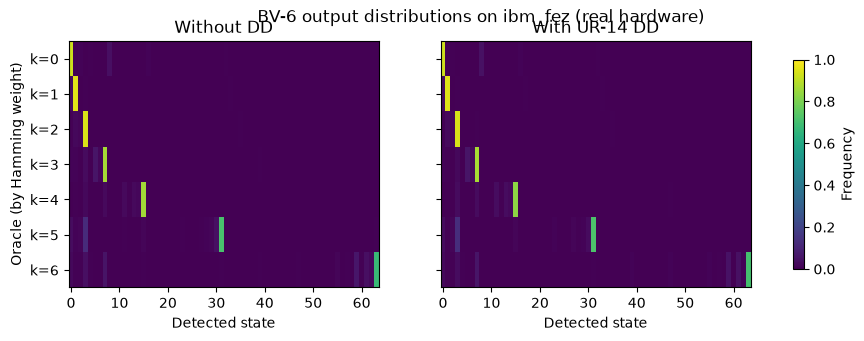

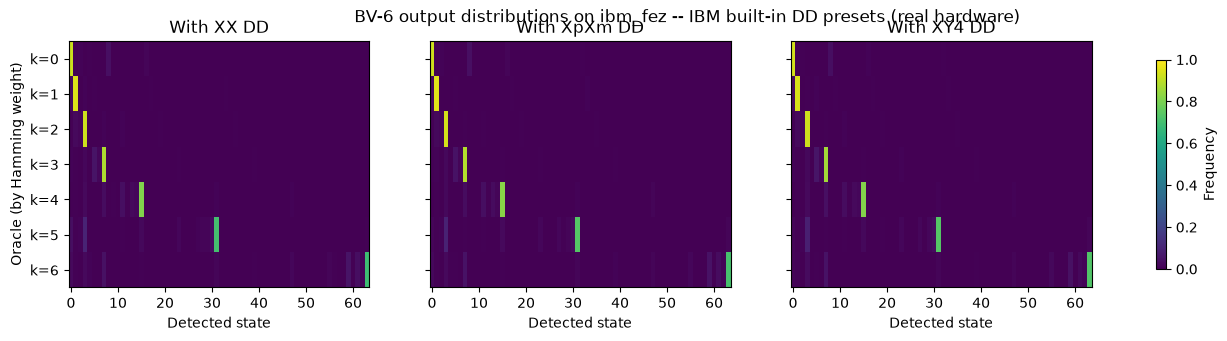

In [12]:
if job is not None:
    hw_result = job.result()
    hw_counts = bv.counts_from_sampler_result(hw_result, len(all_circuits))
    hw_free = dict(zip(labels, hw_counts[: len(labels)]))
    hw_dd = dict(zip(labels, hw_counts[len(labels):]))

    hw_builtin = {}
    for name, bjob in builtin_jobs.items():
        bw_result = bjob.result()
        bw_counts = bv.counts_from_sampler_result(bw_result, len(labels))
        hw_builtin[name] = dict(zip(labels, bw_counts))

    hw_comparison = bv.compare_variants({"free": hw_free, "dd": hw_dd, **hw_builtin}, labels)
    display(hw_comparison)
    print("Average success probability -- " + ", ".join(f"{col}: {hw_comparison[col].mean():.3f}" for col in variant_cols))

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
    _, im0 = bv.plot_output_distributions(hw_free, labels, N, "Without DD", ax=axes[0])
    _, im1 = bv.plot_output_distributions(hw_dd, labels, N, "With UR-14 DD", ax=axes[1])
    axes[0].set_ylabel("Oracle (by Hamming weight)")
    fig.colorbar(im1, ax=axes, label="Frequency", shrink=0.85)
    fig.suptitle(f"BV-{N} output distributions on {backend.name} (real hardware)")
    plt.show()

    if hw_builtin:
        fig2, axes2 = plt.subplots(1, len(hw_builtin), figsize=(5.5 * len(hw_builtin), 3.2), sharey=True)
        for ax, name in zip(axes2, hw_builtin):
            _, im2 = bv.plot_output_distributions(hw_builtin[name], labels, N, f"With {name} DD", ax=ax)
        axes2[0].set_ylabel("Oracle (by Hamming weight)")
        fig2.colorbar(im2, ax=axes2, label="Frequency", shrink=0.85)
        fig2.suptitle(f"BV-{N} output distributions on {backend.name} -- IBM built-in DD presets (real hardware)")
        plt.show()
else:
    print("No hardware job was submitted in this run -- set SUBMIT = True in Section 8 to run on real hardware.")

## Next steps

- Experiment 1's own idle-time-utilization diagnostic (Section 4a) found DD
  mostly not applied at N=6 (idle windows shorter than a full sequence
  application, plus `skip_reset_qubits` suppressing early windows) --
  consistent with the inconclusive free-vs-DD result in Section 9.
  `bv_dd_experiment2_n_sweep.ipynb` follows up with a multi-*n* sweep to
  test whether longer circuits (longer idle windows) change that.
- Time-to-solution scaling, bootstrapped confidence intervals, and the
  worst-case speedup exponent &lambda; (Eq. 2) remain deferred beyond that.
- The custom CNOT-efficient ancilla-swap router (Appendix D) is still on
  the shelf -- see `Experiment Plan.md` for why, and revisit once N-scaling
  is validated.

See `Experiment Plan.md` for the full experiment log and design-decisions
record shared across all notebooks in this project.

In [14]:
import inspect
from qiskit_ibm_runtime.options.dynamical_decoupling_options import DynamicalDecouplingOptions
print(inspect.getsource(DynamicalDecouplingOptions))


@primitive_dataclass
class DynamicalDecouplingOptions:
    """Options for dynamical decoupling (DD)."""

    enable: UnsetType | bool = Unset
    """Whether to enable DD as specified by the other options in this class.

    Default: ``False``.
    """

    sequence_type: UnsetType | Literal["XX", "XpXm", "XY4"] = Unset
    """Which dynamical decoupling sequence to use.

        Default: ``"XX"``.

        * ``"XX"``: use the sequence ``tau/2 - (+X) - tau - (+X) - tau/2``
        * ``"XpXm"``: use the sequence ``tau/2 - (+X) - tau - (-X) - tau/2``
        * ``"XY4"``: use the sequence
          ``tau/2 - (+X) - tau - (+Y) - tau (-X) - tau - (-Y) - tau/2``
    """

    extra_slack_distribution: UnsetType | Literal["middle", "edges"] = Unset
    """Where to put extra timing delays due to rounding issues.

    Rounding issues arise because the discrete time step ``dt`` of the system cannot
    be divided. This option takes following values.

    Default: ``"middle"``.

    * ``"middle"``: 